In [1]:
# Phase 1: Dataset load + EDA — Credit Card Fraud Detection
# Dataset: Kaggle "Credit Card Fraud Detection" (mlg-ulb) -> creditcard.csv
# Works as a script or paste cell-by-cell into Jupyter.

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("plots", exist_ok=True)



In [2]:
# load dataset
df = pd.read_csv("data/creditcard.csv")
print("Shape:", df.shape)
print(df.head(5))


Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26 

In [3]:

Missing_values = df.isnull().sum().sum()
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1081


Class
0    284315
1       492
Name: count, dtype: int64
Fraud %: 0.1727


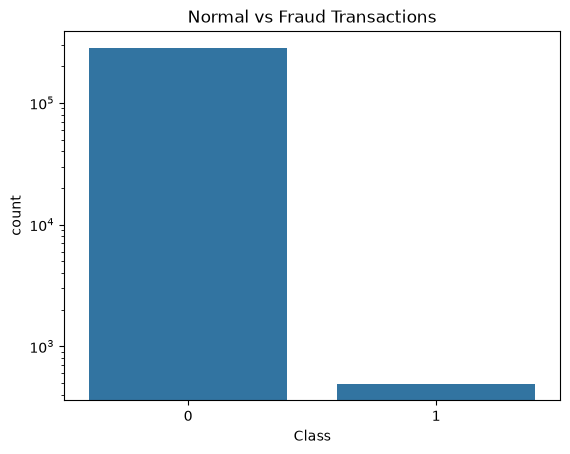

In [4]:
# Class imbalance 
print(df["Class"].value_counts())
print("Fraud %:", round(df["Class"].mean() * 100, 4))

sns.countplot(x="Class", data=df)
plt.yscale("log")  # log scale, otherwise the fraud bar is too small to see
plt.title("Normal vs Fraud Transactions")
plt.savefig("plots/01_class_count.png", dpi=150)
plt.show()


          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


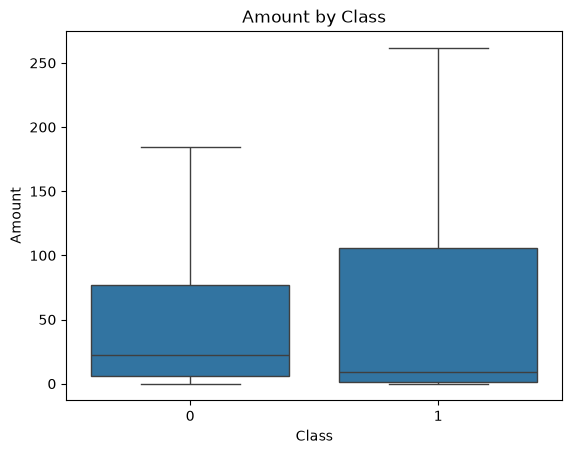

In [5]:
#                    Amount analysis 
print(df.groupby("Class")["Amount"].describe())

sns.boxplot(x="Class", y="Amount", data=df, showfliers=False)
plt.title("Amount by Class")
plt.savefig("plots/02_amount.png", dpi=150)
plt.show()


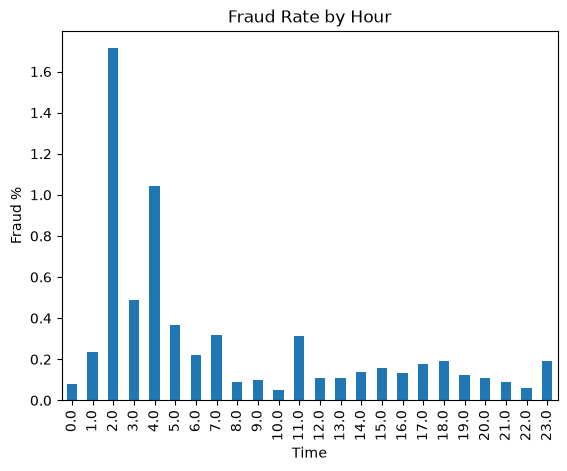

In [6]:

#  Time analysis --------
# Time is in seconds, so convert it to hour of the day
hour = (df["Time"] // 3600) % 24
fraud_by_hour = df.groupby(hour)["Class"].mean() * 100

fraud_by_hour.plot(kind="bar")
plt.ylabel("Fraud %")
plt.title("Fraud Rate by Hour")
plt.savefig("plots/03_hour.png", dpi=150)
plt.show()

Most negative:
 V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
Most positive:
 V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


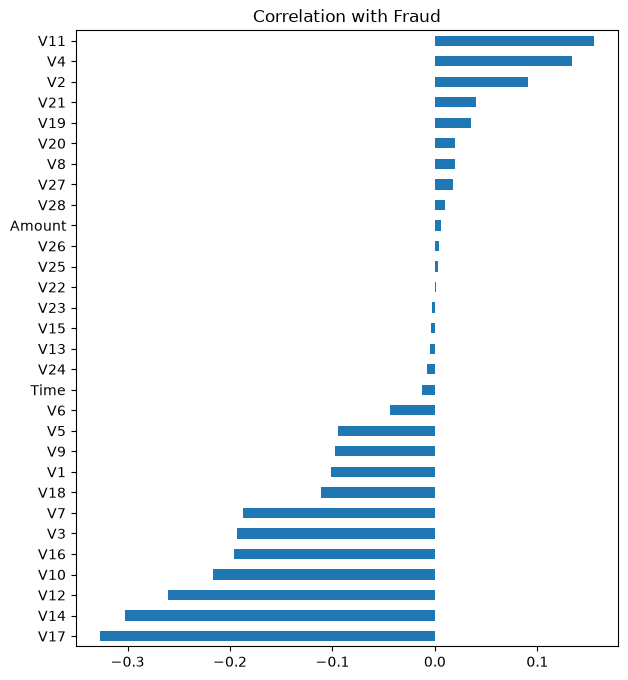

In [7]:
#  Correlation with fraud
corr = df.corr()["Class"].drop("Class").sort_values()
print("Most negative:\n", corr.head(5))
print("Most positive:\n", corr.tail(5))

corr.plot(kind="barh", figsize=(7, 8))
plt.title("Correlation with Fraud")
plt.savefig("plots/04_corr.png", dpi=150)
plt.show()

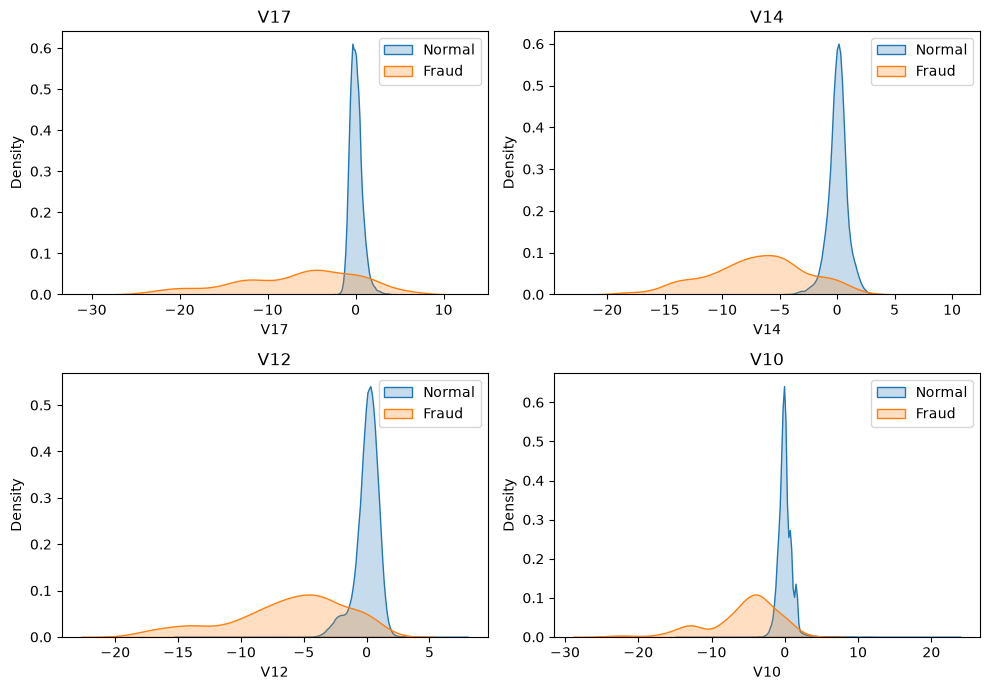

In [8]:

# Top 4 features
top4 = corr.abs().sort_values(ascending=False).head(4).index

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), top4):
    sns.kdeplot(df[df["Class"] == 0][col], ax=ax, label="Normal", fill=True)
    sns.kdeplot(df[df["Class"] == 1][col], ax=ax, label="Fraud", fill=True)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.savefig("plots/05_top_features.png", dpi=150)
plt.show()

In [9]:
### Baseline, class weight, SMOTE

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix)
from imblearn.over_sampling import SMOTE

## Clean and split

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

X = df.drop(columns=["Class"])
y = df["Class"]

# stratify keeps the same fraud % in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train frauds:", y_train.sum(), "| Test frauds:", y_test.sum())

Shape after removing duplicates: (283726, 31)
Train frauds: 378 | Test frauds: 95


In [12]:
#                          Scale Time and Amount
cols = ["Time", "Amount"]
scaler = RobustScaler()
X_train[cols] = scaler.fit_transform(X_train[cols])  # fit on train only
X_test[cols] = scaler.transform(X_test[cols])

In [13]:
#                         Function to check a model
results = []

def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "PR-AUC": round(average_precision_score(y_test, proba), 4),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 4),
        "Precision": round(precision_score(y_test, pred), 4),
        "Recall": round(recall_score(y_test, pred), 4),
        "F1": round(f1_score(y_test, pred), 4)
    })
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(name, "-> caught:", tp, "| missed:", fn, "| false alarms:", fp)


In [14]:

lr_base = LogisticRegression(max_iter=2000, random_state=42)
lr_base.fit(X_train, y_train)
evaluate("A: Baseline LR", lr_base)

A: Baseline LR -> caught: 56 | missed: 39 | false alarms: 9


In [15]:
lr_weighted = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
lr_weighted.fit(X_train, y_train)
evaluate("B: LR + class_weight", lr_weighted)

B: LR + class_weight -> caught: 83 | missed: 12 | false alarms: 1393


In [16]:
# SMOTE makes synthetic fraud rows, only for training data
X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("After SMOTE:", y_res.value_counts().to_dict())

lr_smote = LogisticRegression(max_iter=2000, random_state=42)
lr_smote.fit(X_res, y_res)
evaluate("C: LR + SMOTE", lr_smote)  # test data is not touched

After SMOTE: {0: 226602, 1: 226602}
C: LR + SMOTE -> caught: 83 | missed: 12 | false alarms: 1463


In [17]:
pd.DataFrame(results)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1
0,A: Baseline LR,0.6951,0.9575,0.8615,0.5895,0.7000
1,B: LR + class_weight,0.6719,0.9657,0.0562,0.8737,0.1057
2,C: LR + SMOTE,0.6729,0.9600,0.0537,0.8737,0.1012


In [18]:
## model comparison

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [20]:
# ratio of normal transactions to fraud transactions
# XGBoost uses this to give more importance to fraud cases
ratio = (y_train == 0).sum() / (y_train == 1).sum()

lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr", random_state=42)

models = {"Logistic Regression": lr, "Random Forest": rf, "XGBoost": xgb}

In [21]:
# split training data into 5 parts, keeping the fraud ratio the same in each part
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=["average_precision", "roc_auc"])
    cv_results.append({
        "Model": name,
        "PR-AUC": scores["test_average_precision"].mean().round(4),
        "PR-AUC std": scores["test_average_precision"].std().round(4),
        "ROC-AUC": scores["test_roc_auc"].mean().round(4)
    })
    print(name, "done")

cv_df = pd.DataFrame(cv_results)
cv_df

Logistic Regression done
Random Forest done
XGBoost done


,Model,PR-AUC,PR-AUC std,ROC-AUC
0,Logistic Regression,0.7543,0.0265,0.9814
1,Random Forest,0.8334,0.0271,0.9541
2,XGBoost,0.8443,0.0264,0.9796


In [22]:
# pick the model with the highest PR-AUC from cross validation
best_name = cv_df.sort_values("PR-AUC").iloc[-1]["Model"]
print("Best model:", best_name)

# train it on the full training data and check it on the test data
best_model = models[best_name]
best_model.fit(X_train, y_train)
evaluate("Best: " + best_name, best_model)

pd.DataFrame(results)

Best model: XGBoost
Best: XGBoost -> caught: 75 | missed: 20 | false alarms: 6


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1
0,A: Baseline LR,0.6951,0.9575,0.8615,0.5895,0.7000
1,B: LR + class_weight,0.6719,0.9657,0.0562,0.8737,0.1057
2,C: LR + SMOTE,0.6729,0.9600,0.0537,0.8737,0.1012
3,Best: XGBoost,0.8143,0.9631,0.9259,0.7895,0.8523


In [24]:
from sklearn.model_selection import cross_val_predict
import shap

In [25]:
# Fraud probability for every training row
# each row is predicted by a model that did not see that row in training
train_proba = cross_val_predict(xgb, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

Best threshold: 0.28


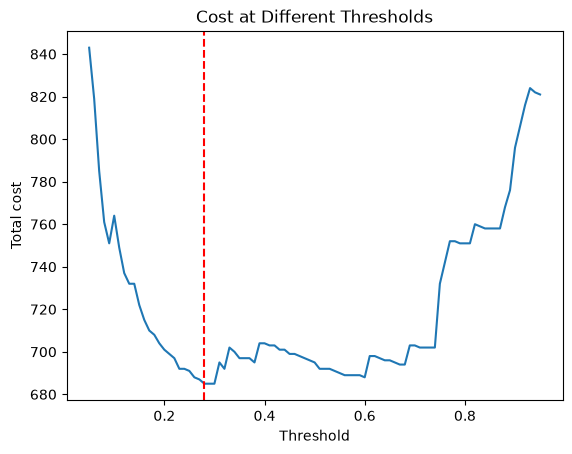

In [26]:
#Find the best threshold using cost
cost_missed = 10  # cost of missing one fraud (assumption)
cost_false = 1    # cost of one false alarm (assumption)

thresholds = np.arange(0.05, 0.96, 0.01)
costs = []

for t in thresholds:
    pred = (train_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    costs.append(fn * cost_missed + fp * cost_false)

best_t = thresholds[np.argmin(costs)]
print("Best threshold:", round(best_t, 2))

plt.plot(thresholds, costs)
plt.axvline(best_t, color="red", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Total cost")
plt.title("Cost at Different Thresholds")
plt.savefig("plots/06_cost_curve.png", dpi=150)
plt.show()

In [27]:
# Compare 0.5 with the best threshold on the test set
test_proba = best_model.predict_proba(X_test)[:, 1]

for t in [0.5, best_t]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print("Threshold", round(t, 2),
          "| caught:", tp, "| missed:", fn, "| false alarms:", fp,
          "| precision:", round(precision_score(y_test, pred), 3),
          "| recall:", round(recall_score(y_test, pred), 3))

Threshold 0.5 | caught: 75 | missed: 20 | false alarms: 6 | precision: 0.926 | recall: 0.789
Threshold 0.28 | caught: 76 | missed: 19 | false alarms: 21 | precision: 0.784 | recall: 0.8


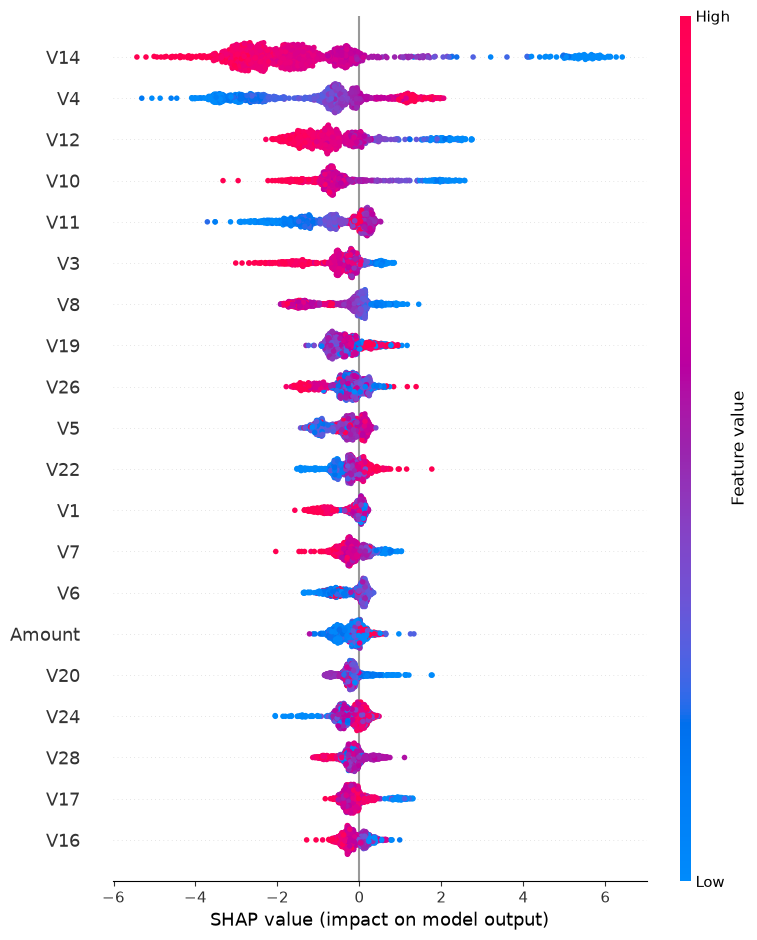

In [28]:
# SHAP, which features drive fraud
# use all test frauds plus 1000 normal rows
fraud_rows = X_test[y_test == 1]
normal_rows = X_test[y_test == 0].sample(1000, random_state=42)
sample = pd.concat([fraud_rows, normal_rows])

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, show=False)
plt.savefig("plots/07_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [29]:
import joblib

os.makedirs("model", exist_ok=True)
joblib.dump(best_model, "model/xgb_model.pkl")      # trained XGBoost
joblib.dump(scaler, "model/scaler.pkl")             # scaler for Time and Amount
joblib.dump(list(X_train.columns), "model/columns.pkl")  # column order

# small sample of real test transactions (unscaled) for the app demo
test_raw = df.loc[X_test.index]
demo = pd.concat([test_raw[test_raw["Class"] == 1].head(20),
                  test_raw[test_raw["Class"] == 0].sample(80, random_state=42)])
demo.sample(frac=1, random_state=42).to_csv("model/demo_transactions.csv", index=False)